In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
from skophys.utils import rolling_percentile

In [3]:
%matplotlib inline

In [4]:
path = "/home/kushal/caiman_data/example_movies/Sue_2x_3000_40_-46_els__d1_170_d2_170_d3_1_order_F_frames_3000.mmap"
movie = np.memmap(path, dtype=np.float32, order="F", shape=(170, 170, 3_000)).T

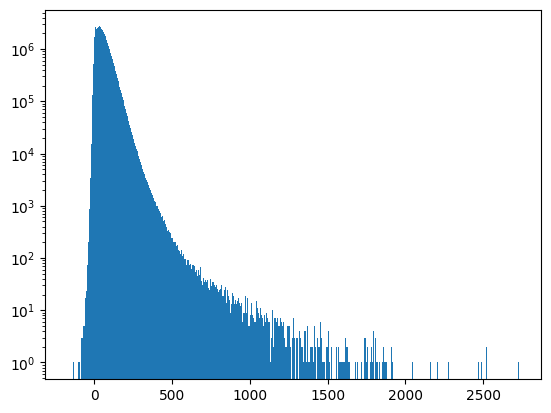

In [5]:
plt.hist(movie.ravel(), bins=1_000)
plt.semilogy()
plt.show()

In [7]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  movie[:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [60]:
iw_movie.window_funcs = {"t": (np.mean, 11)}

In [20]:
filt_movie = rolling_percentile(movie, window_size=10, quantile=2)

In [21]:
iw_movie.set_data(filt_movie, reset_indices=False)

In [22]:
from sklearn.preprocessing import RobustScaler

In [24]:
filt_movie.shape

(3000, 170, 170)

In [29]:
Y = filt_movie.T.reshape(np.prod(filt_movie.shape[1:]), filt_movie.shape[0])

In [30]:
ss = RobustScaler()

In [31]:
Y = ss.fit_transform(Y.T)
Y = Y.T

In [32]:
Y

array([[-0.08076017, -0.08076017, -0.08076017, ...,  1.1924529 ,
         1.1765018 , -0.3574109 ],
       [-0.65235317, -0.63154083,  0.13596235, ...,  0.05169701,
         0.07376046, -0.5267831 ],
       [ 0.0379567 ,  0.0379567 ,  0.0379567 , ...,  0.58546203,
         0.553323  , -0.38703334],
       ...,
       [ 0.5497662 , -0.14845373, -0.14845373, ...,  0.9630973 ,
         2.0529535 , -0.71005464],
       [ 0.7671027 ,  0.7671027 ,  0.8267212 , ..., -0.3895258 ,
        -0.4193702 , -0.34393397],
       [-0.21095106, -0.21095106, -1.2432165 , ...,  5.5037966 ,
         6.1189866 , -0.29816085]], dtype=float32)

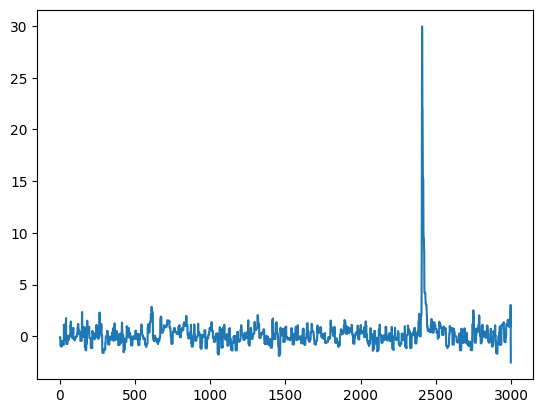

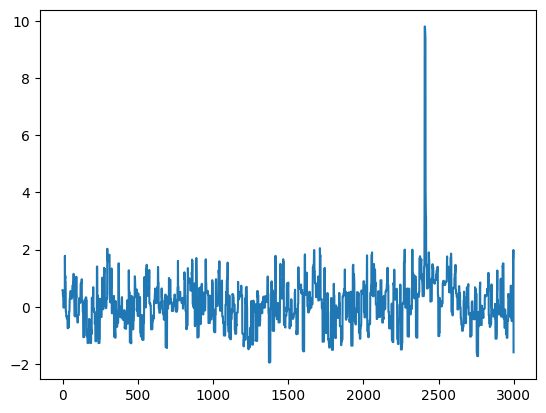

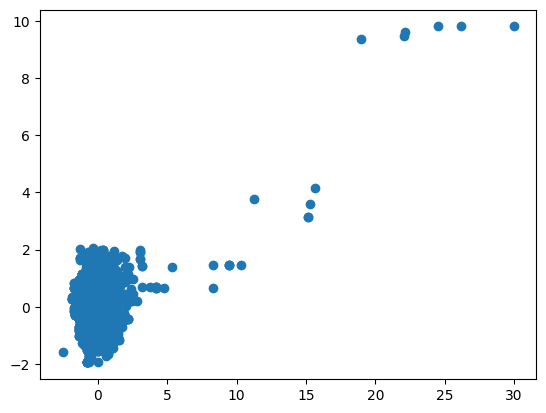

In [33]:
i1 = 1202
i2 = 1203

u = Y[i1]
v = Y[i2]

plt.plot(u)
plt.show()
plt.plot(v)
plt.show()

plt.scatter(Y[i1, :], Y[i2, :])
plt.show()
# plt.scatter(projections[:, 0], projections[:, 1])

In [34]:
Y.shape

(28900, 3000)

In [35]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [36]:
@njit(parallel=True)
def get_distances(
    i: int, 
    Y: np.ndarray, 
    ysum: np.ndarray, 
    projections: np.ndarray,
    output: np.ndarray
):
    for j in prange(Y.shape[0]):
        i_dot_j = np.dot(Y[i], Y[j])
        i_dot_i = np.dot(Y[i], Y[i])
        m = (i_dot_j - 1 / Y.shape[1] * ysum[i] * ysum[j]) / (i_dot_i - 1 / Y.shape[1] * ysum[i]**2)
        
        v1 = np.array([m, 1])

        x = Y[i, :]
        y = Y[j, :]
        
        # Step 1: Calculate means of x and y
        x_mean = np.mean(x)
        y_mean = np.mean(y)
        
        v1[0] += x_mean
        v1[1] += y_mean

        denom = np.sqrt(v1.sum())
        v1[0] = v1[0] / denom
        v1[1] = v1[1] / denom

        v1 /= np.sqrt(np.sum(v1**2))
        
        X = np.zeros((x.size, 2))
        X[:, 0] = x
        X[:, 1] = y
        
        projections_pre = (X @ v1)
        
        projections[j, :, 0] = projections_pre * v1[0]
        projections[j, :, 1] = projections_pre * v1[1]

        orthogonal_distances = X - projections[j]  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
        # orthogonal_distances = orthogonal_distances**2
        
        # # # Sum of orthogonal distances
        # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000

        output[j] = s**2

In [37]:
ysum = np.sum(Y, axis=1)
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))

In [52]:
get_distances(
    8523,
    Y,
    ysum,
    projections,
    output_matrix
)

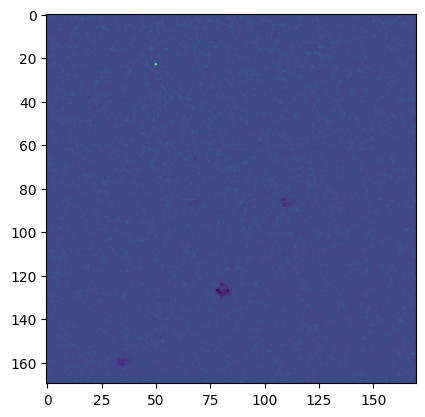

In [53]:
plt.imshow(output_matrix.reshape(movie.shape[2], movie.shape[1]).T, cmap="viridis_r")
plt.show()

In [54]:
projections.shape

(28900, 3000, 2)

In [56]:
std = filt_movie.std(axis=0)

In [59]:
iw = fpl.ImageWidget([std, np.zeros(std.shape)], cmap="viridis")

pixel_index_A = 0
projections = np.zeros((*Y.shape, 2))

pixel_A_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="magenta")
pixel_B_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="cyan")

@iw.managed_graphics[0].add_event_handler("double_click")
def update_distance_image(ev):
    global pixel_index_A
    global projections
    
    col, row = ev.pick_info["index"]

    i = np.ravel_multi_index((col, row), (movie.shape[2], movie.shape[1]))
    
    pixel_index_A = i

    pixel_A_pt.data[0, 0] = col
    pixel_A_pt.data[0, 1] = row
    
    output_matrix = np.zeros((Y.shape[0],))
    projections = np.zeros((*Y.shape, 2))
    get_distances(
        i,
        Y,
        ysum,
        projections,
        output_matrix
    )
    
    iw.managed_graphics[1].data = output_matrix.reshape(movie.shape[2], movie.shape[1]).T
    iw.reset_vmin_vmax()


fig_s = fpl.Figure(shape=(1, 2))

scatter_corr = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors=(1, 0.7, 0, 0.3), alpha=0.3)
scatter_proj = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors="r", alpha=0.3)
fig_s[0, 0].axes.colors = ("magenta", "cyan", "w")

line_p1 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="magenta", alpha=0.3)
line_p2 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="cyan", alpha=0.3)

selector_time = line_p1.add_linear_selector()

@iw.managed_graphics[1].add_event_handler("double_click")
def update_scatters(ev):
    u = Y[pixel_index_A]

    col, row = ev.pick_info["index"]

    j = np.ravel_multi_index((col, row), (movie.shape[2], movie.shape[1]))
    v = Y[j]

    pixel_B_pt.data[0, 0] = col
    pixel_B_pt.data[0, 1] = row
    
    scatter_corr.data[:, :-1] = np.column_stack([u, v])
    scatter_proj.data[:, :-1] = projections[j]
    fig_s[0, 0].auto_scale(maintain_aspect=False)

    line_p1.data[:, 1] = u
    line_p2.data[:, 1] = v
    fig_s[0, 1].auto_scale(maintain_aspect=False)

@selector_time.add_event_handler("selection")
def update_selected_time(ev):
    t = ev.get_selected_index()
    scatter_corr.colors = (1, 0.7, 0, 0.3)
    scatter_corr.sizes = 4
    
    scatter_corr.colors[t] = "w"
    scatter_corr.sizes[t] = 20


iw.cmap = ["viridis", "viridis_r"]

VBox([iw.show(), fig_s.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

In [95]:
pixel_A_pt.data

VertexPositions buffer data:
array([[26., 46.,  0.]], dtype=float32)

In [96]:
pixel_B_pt.data

VertexPositions buffer data:
array([[33., 33.,  0.]], dtype=float32)

# Plot time series of the two pixels, linear region selector to highlight scatter point
# click on scatter point, set linear region selector timepoint